# E3. Huấn luyện và so sánh model

Đây là bước Model training và evaluation của ML pipeline. Trên cùng dữ liệu và cùng 5 fold (`data/folds.csv`), nhóm
so sánh các họ model phân lớp của Bài 07 (Naive Bayes, cây quyết định, SVM, Logistic Regression), Bài 08 (bagging,
boosting) và mạng nơ-ron, đồng thời đo bias / variance (khoảng cách giữa AUC train và AUC validation) và learning
curve.

> **Trong cuộc thi.** Sau model LightGBM đầu tiên (14/10), từ 15 đến 25/10 nhóm train thêm nhiều loại model khác:
> Logistic Regression, kNN, TabM, Factorization Machine, FT-Transformer, TabPFN, GPT-2, XGBoost và CatBoost dùng
> teacher từ dữ liệu gốc, RealMLP, và Q-FT (transformer nhóm tự viết, tiền huấn luyện rồi fine-tune). Mục đích lúc
> đó là tìm model khác biệt để đưa vào stacking (E5) hơn là tìm một model đơn tốt nhất. Mục 1 tổng hợp các model này.

Nội dung:
1. Các model nhóm đã train khi thi: CV, tương quan với LightGBM, đóng góp vào stacking
2. So sánh 14 model trên cùng đầu vào (chạy trên máy cá nhân và Kaggle), kèm bias / variance theo độ sâu cây
3. Learning curve của LightGBM
4. Tương quan giữa các model
5. Tóm tắt và quyết định

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.exceptions import ConvergenceWarning
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

from blend import lr_stack, meta_folds, to_logit
from config import CAT_COLS, FEATURES, N_FOLDS, NUM_COLS, OOF_DIR, RESULTS_DIR, ROOT, SCORE_COLS, TARGET
from data import load_data
import plot as P

pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
train, test = load_data()
y, fold = train[TARGET].values, train["fold"].values
AGE, FD, DEP, ARR = NUM_COLS
OOF_DIR.mkdir(exist_ok=True)
KAGGLE_DIR = RESULTS_DIR / "E3_models"  # output kernel thanhmn123/cs116-e3-models (exp/kaggle/E3_models.py)
COMP_OOF = Path(os.environ.get("COMP_OOF_DIR", ROOT.parent / "DoAn" / "oof"))  # OOF lưu khi thi

## 1. Các model nhóm đã train khi thi

Phần này đọc lại các file OOF lưu khi thi của cả 3 thành viên (cùng `folds.csv`). Theo quy ước ở E0, chỉ OOF sạch
được đưa vào stacking, nên hai file early stopping trên fold đang chấm bị loại: `A_kozy_esval_v1` (khi thi chỉ dùng
để đo ảnh hưởng của lỗi này) và Dual-Specialist LightGBM (vẫn có một dòng trong bảng để ghi AUC).

Với mỗi họ model, bảng ghi model đại diện, CV AUC, tương quan rank với LightGBM của nhóm và Δ stack khi bỏ cả họ. Δ
được tính như sau: stacking bằng LR trên logit của 25 OOF sạch (`src/blend.py`, C = 0,003), bỏ mọi file của họ đó rồi
đo lại, trên 2 cách chia meta fold (`folds.csv` và seed 7). Δ âm nghĩa là họ đó có đóng góp.

Kết quả tính một lần rồi lưu `results/E3_competition_models.csv` (OOF khi thi không nằm trong repo này).

In [2]:
FAMILIES = {  # họ -> (file OOF thuộc họ, model đại diện)
    "LightGBM + feature (E2)": (["A_lgb_v1", "A_lgb_v2", "A_lgb_origrow_v1", "A_lgb_noorig_v1", "A_lgb_wper3_v1"], "A_lgb_v2"),
    "XGBoost / CatBoost dùng dữ liệu gốc (teacher hoặc ghép dòng)": (["quan_cat_dual_teacher_v4", "quan_xgb_dual_teacher_v4",
                                                "quan_xgb_safe_teacher_v4", "quan_xgb_original_aug_v4"],
                                               "quan_cat_dual_teacher_v4"),
    "LightGBM feature nghiệp vụ (chạy lại member công khai)": (["A_kozy_v1", "A_kozy_raw_v1", "A_kozy_prior_v1"],
                                                              "A_kozy_v1"),
    "Logistic Regression (one-hot thưa, E2)": (["A_lr_v1", "A_lr_v2"], "A_lr_v2"),
    "LR + token GPT-2 của chuỗi số": (["A_glr_v1"], "A_glr_v1"),
    "kNN": (["A_knn_v1", "A_knn_v2"], "A_knn_v2"),
    "Factorization Machine": (["A_fm_v1"], "A_fm_v1"),
    "TabM": (["A_tabm_v1"], "A_tabm_v1"),
    "FT-Transformer": (["A_ftt_v1"], "A_ftt_v1"),
    "RealMLP-TD (pytabkit, 16 epoch, + 6 feature tổng hợp)": (["B_realmlp_v1"], "B_realmlp_v1"),
    "GPT-2 phân loại dòng dạng văn bản": (["A_gptc_v1"], "A_gptc_v1"),
    "Q-FT (transformer tự viết, tiền huấn luyện RTD)": (["A_qft2_v2", "A_qft2_v2s7", "A_qft2_v2avg"], "A_qft2_v2"),
    "LightGBM 2 nhánh Personal / Business Travel (dừng sớm trên fold đang chấm)": (["B_personal_spec_v1"], "B_personal_spec_v1"),
}
SHOW = {"A_lgb_v2": "LightGBM bậc 4 + teacher (bản sửa lỗi FD/Age)", "quan_cat_dual_teacher_v4": "CatBoost + 2 teacher gốc",
        "A_kozy_v1": "LightGBM feature nghiệp vụ + prior gốc", "A_lr_v2": "LR one-hot thưa (L6)", "A_glr_v1": "LR + token GPT-2",
        "A_knn_v2": "kNN k=50", "A_fm_v1": "FM dim 16", "A_tabm_v1": "TabM", "A_ftt_v1": "FT-Transformer d64 3 lớp",
        "B_realmlp_v1": "RealMLP-TD, batch 2048", "A_gptc_v1": "GPT-2 phân loại", "A_qft2_v2": "Q-FT v2 (seed 42)",
        "B_personal_spec_v1": "Dual-Specialist LightGBM"}
NOT_CLEAN = {"B_personal_spec_v1"}  # có dòng trong bảng nhưng không vào stack
DATES = {"quan_cat_dual_teacher_v4": "17/10", "B_realmlp_v1": "19/10", "B_personal_spec_v1": "–"}
comp_path = RESULTS_DIR / "E3_competition_models.csv"

if not comp_path.exists():
    log = pd.read_csv(RESULTS_DIR / "competition_log.csv").set_index("model")
    all_names = [n for files, _ in FAMILIES.values() for n in files]
    names = [n for n in all_names if n not in NOT_CLEAN]
    oofs = {n: np.load(COMP_OOF / f"oof_{n}.npy") for n in all_names}
    Z = {n: to_logit(o, o)[0] for n, o in oofs.items()}
    lgb_rank = rankdata(oofs["A_lgb_v2"])

    def stack_auc(cols, folds):
        X = np.column_stack([Z[n] for n in cols])
        oof, _, _ = lr_stack(X, y, X[:1], folds)
        return roc_auc_score(y, oof)

    seeds = {"folds.csv": fold, "seed 7": meta_folds(y, 7)}
    full = {s: stack_auc(names, f) for s, f in seeds.items()}
    print(f"stack {len(names)} OOF:", {s: round(v, 6) for s, v in full.items()})
    rows = []
    for fam, (files, rep) in FAMILIES.items():
        t0 = time.time()
        rest = [n for n in names if n not in files]
        in_stack = rest != names
        d = {s: (stack_auc(rest, f) - full[s]) if in_stack else np.nan for s, f in seeds.items()}
        date = DATES.get(rep) or pd.to_datetime(log.loc[rep, "date"]).strftime("%d/%m")
        rows.append({"họ": fam, "model đại diện": SHOW[rep], "ngày": date, "số file": len(files),
                     "cv_auc": round(roc_auc_score(y, oofs[rep]), 6),
                     "rank_corr_lgb": round(float(np.corrcoef(rankdata(oofs[rep]), lgb_rank)[0, 1]), 4),
                     "trong stack": "có" if in_stack else "không (không sạch)",
                     "delta_stack_folds": round(d["folds.csv"], 6), "delta_stack_seed7": round(d["seed 7"], 6)})
        print(f"{fam:60s} Δ {d['folds.csv']:+.6f} / {d['seed 7']:+.6f} ({time.time() - t0:.0f}s)")
    comp = pd.DataFrame(rows)
    comp.attrs["full"] = full
    comp.to_csv(comp_path, index=False)
    full["n_oof"] = len(names)
    pd.DataFrame([full]).to_csv(RESULTS_DIR / "E3_team_stack_full.csv", index=False)

comp = pd.read_csv(comp_path)
full = pd.read_csv(RESULTS_DIR / "E3_team_stack_full.csv").iloc[0]
print(f"Stack LR {int(full['n_oof'])} OOF sạch của nhóm: {full['folds.csv']:.6f} (meta fold = folds.csv), {full['seed 7']:.6f} (seed 7)")
comp.sort_values("cv_auc", ascending=False).set_index("họ")

Stack LR 25 OOF sạch của nhóm: 0.961619 (meta fold = folds.csv), 0.961626 (seed 7)


,model đại diện,ngày,số file,cv_auc,rank_corr_lgb,trong stack,delta_stack_folds,delta_stack_seed7
họ,,,,,,,,
"Q-FT (transformer tự viết, tiền huấn luyện RTD)",Q-FT v2 (seed 42),25/10,3,0.961091,0.9659,có,-0.000225,-0.000222
XGBoost / CatBoost dùng dữ liệu gốc (teacher hoặc ghép dòng),CatBoost + 2 teacher gốc,17/10,4,0.960941,0.9804,có,-0.000027,-0.000025
LightGBM + feature (E2),LightGBM bậc 4 + teacher (bản sửa lỗi FD/Age),18/10,5,0.960893,1.0000,có,-0.000051,-0.000051
FT-Transformer,FT-Transformer d64 3 lớp,18/10,1,0.960050,0.9660,có,0.000005,0.000005
LR + token GPT-2 của chuỗi số,LR + token GPT-2,18/10,1,0.959867,0.9587,có,-0.000016,-0.000016
"Logistic Regression (one-hot thưa, E2)",LR one-hot thưa (L6),18/10,2,0.959737,0.9594,có,-0.000011,-0.000007
TabM,TabM,15/10,1,0.959541,0.9459,có,0.000004,0.000004
LightGBM feature nghiệp vụ (chạy lại member công khai),LightGBM feature nghiệp vụ + prior gốc,19/10,3,0.958661,0.9430,có,0.000000,0.000000
LightGBM 2 nhánh Personal / Business Travel (dừng sớm trên fold đang chấm),Dual-Specialist LightGBM,–,1,0.958643,0.9385,không (không sạch),NaN,NaN


Mọi file OOF trong bảng đều có code trong `exp/competition/code/`, trừ `A_qft2_v2avg`. Khi thi, file này được tính
trực tiếp bằng trung bình logit của hai seed Q-FT (`A_qft2.py`, seed 42 và seed 7). Ô dưới tính lại và so với file
đã dùng.

In [3]:
def qft2_avg(part):
    """A_qft2_v2avg = sigmoid(trung bình logit của Q-FT seed 42 và seed 7)."""
    a, b = (np.load(COMP_OOF / f"{part}_A_qft2_{n}.npy").astype(np.float64) for n in ("v2", "v2s7"))
    lg = lambda p: np.log(p / (1 - p))  # noqa: E731
    return 1 / (1 + np.exp(-(lg(a) + lg(b)) / 2))


if (COMP_OOF / "oof_A_qft2_v2avg.npy").exists():
    for part in ("oof", "test"):
        old = np.load(COMP_OOF / f"{part}_A_qft2_v2avg.npy").astype(np.float64)
        new = qft2_avg(part)
        lg = lambda p: np.log(p / (1 - p))  # noqa: E731
        print(f"{part}: chênh lệch logit lớn nhất {np.abs(lg(new) - lg(old)).max():.1e}")
    print(f"AUC OOF tính lại {roc_auc_score(y, qft2_avg('oof')):.6f}")

oof: chênh lệch logit lớn nhất 0.0e+00
test: chênh lệch logit lớn nhất 0.0e+00


AUC OOF tính lại 0.961304


**Nhận xét mục 1**
- Stacking 25 OOF sạch của nhóm đạt **0,961619** (0,961626 với meta fold seed 7), cao hơn LightGBM đơn của nhóm
  (0,960893) 7,3×10⁻⁴ và cao hơn model đơn tốt nhất (Q-FT v2, 0,961091) 5,3×10⁻⁴.
- Q-FT đóng góp nhiều nhất. Bỏ cả họ Q-FT thì AUC của stacking giảm 2,25×10⁻⁴, như nhau ở cả 2 cách chia meta fold,
  gấp khoảng 4 lần họ đứng thứ hai. Tương quan rank giữa Q-FT và LightGBM vẫn cao (0,966); một cách giải thích có thể
  là Q-FT học theo cách khác (tiền huấn luyện tự giám sát rồi fine-tune) nên sai ở những dòng khác với model cây,
  nhưng phần này nhóm chưa kiểm chứng trực tiếp.
- Ngoài Q-FT, chỉ 4 họ có Δ từ −1×10⁻⁵ trở xuống: LightGBM (−5,1×10⁻⁵), XGBoost / CatBoost dùng dữ liệu gốc
  (−2,7×10⁻⁵), LR + token GPT-2 (−1,6×10⁻⁵) và LR (−1,1×10⁻⁵). Các họ còn lại nằm trong ±6×10⁻⁶, nhỏ hơn ngưỡng
  3×10⁻⁵ nhóm dùng khi thi (E0), nên không phân biệt được bỏ hay giữ.
- AUC riêng cao chưa chắc giúp được stacking. FT-Transformer (0,96005, model nơ-ron mạnh thứ hai) và TabM (0,95954)
  đều có Δ khoảng +5×10⁻⁶, trong khi tương quan với LightGBM khá cao (0,946–0,966). Ngược lại kNN có tương quan thấp
  nhất (0,867) nhưng AUC quá thấp (0,9503) nên cũng không giúp.
- Dual-Specialist LightGBM chỉ được ghi AUC, không đưa vào stacking vì early stopping trên fold đang chấm.
  `A_lgb_v1` có lỗi đảo hai cột Flight Distance và Age khi tạo feature, nhưng OOF vẫn sạch nên được giữ như khi thi.

## 2. So sánh model trên cùng đầu vào

Phần này không dùng các feature tạo thêm ở E2, để chênh lệch chỉ đến từ model. Theo quyết định ở E2 có hai dạng đầu
vào:
- dạng cho model cây: 21 cột gốc (category để kiểu `category` hoặc mã số);
- dạng cho model tuyến tính (L1 của E2): one-hot 4 cột category và 13 cột điểm, log1p delay, z-score cho Age,
  Flight Distance và delay.

Tham số chưa được tinh chỉnh (để dành cho E4). Với mỗi model, bảng ghi CV AUC, AUC trên dữ liệu train (mẫu 100 nghìn
dòng của phần train fold) và thời gian chạy. Boosting, bagging và MLP chạy trên Kaggle (`exp/kaggle/E3_models.py`,
CPU 4 luồng); Naive Bayes, cây quyết định, SVM và Logistic Regression chạy trên máy cá nhân (ô dưới, có cache).

In [4]:
def linear_frame(train, test):
    """Dạng L1 của E2 (giống exp/kaggle/E3_models.py): one-hot category + điểm, z-score cột số."""
    def num(df):
        return pd.DataFrame({AGE: df[AGE], FD: df[FD], "ld": np.log1p(df[DEP]), "la": np.log1p(df[ARR].fillna(df[DEP]))})
    A = pd.concat([train, test], ignore_index=True)
    oh = pd.get_dummies(A[CAT_COLS + SCORE_COLS].astype(str), dtype=np.float32)
    nm = num(A)
    nm = (nm - nm.iloc[:len(train)].mean()) / nm.iloc[:len(train)].std()
    M = np.hstack([oh.values, nm.values.astype(np.float32)])
    return M[:len(train)], M[len(train):]


def code_frame(df):
    """21 cột gốc dạng số: category -> mã, Arrival Delay thiếu -> Departure Delay."""
    X = df[FEATURES].copy()
    for c in CAT_COLS:
        X[c] = X[c].astype("category").cat.codes
    X[ARR] = X[ARR].fillna(X[DEP])
    return X.values.astype(np.float32)


Xl, Xl_te = linear_frame(train, test)
Xc, Xc_te = code_frame(train), code_frame(test)
N_CAT_SCORE = len(CAT_COLS) + len(SCORE_COLS)  # 17 cột đầu của code_frame là category / điểm
print("dạng tuyến tính", Xl.shape, "| dạng cây (mã số)", Xc.shape)

LOCAL = RESULTS_DIR / "E3_local.csv"


def score(m, X):
    return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)


def chunked(f, X, size=100_000):
    return np.concatenate([f(X[i:i + size]) for i in range(0, len(X), size)])


def evaluate(name, family, make, X, X_te, fit_n=None, notes=""):
    """5-fold CV; make() -> model sklearn. fit_n: chỉ fit trên mẫu fit_n dòng của phần train fold (SVM kernel)."""
    done = pd.read_csv(LOCAL) if LOCAL.exists() else pd.DataFrame(columns=["model"])
    if name in set(done["model"]) and (OOF_DIR / f"oof_E3_{name}.npy").exists():
        return
    oof, te, aucs, tr_aucs, t0 = np.zeros(len(y)), np.zeros(len(X_te)), [], [], time.time()
    for k in range(N_FOLDS):
        tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
        rng = np.random.default_rng(k)
        fit_idx = tr if fit_n is None else rng.choice(tr, fit_n, replace=False)
        m = make().fit(X[fit_idx], y[fit_idx])
        samp = rng.choice(fit_idx, min(100_000, len(fit_idx)), replace=False)
        oof[va] = chunked(lambda Z: score(m, Z), X[va])
        te += chunked(lambda Z: score(m, Z), X_te) / N_FOLDS
        aucs.append(roc_auc_score(y[va], oof[va]))
        tr_aucs.append(roc_auc_score(y[samp], chunked(lambda Z: score(m, Z), X[samp])))
    row = {"model": name, "family": family, "cv_auc": round(roc_auc_score(y, oof), 6),
           "fold_mean": round(float(np.mean(aucs)), 6), "fold_std": round(float(np.std(aucs)), 6),
           **{f"fold_{k}": round(a, 6) for k, a in enumerate(aucs)},
           "train_auc": round(float(np.mean(tr_aucs)), 6), "minutes": round((time.time() - t0) / 60, 1)}
    row["train_minus_cv"] = round(row["train_auc"] - row["fold_mean"], 6)
    row["notes"] = notes
    done = done[done["model"] != name]
    pd.concat([done, pd.DataFrame([row])], ignore_index=True).to_csv(LOCAL, index=False)
    np.save(OOF_DIR / f"oof_E3_{name}.npy", oof)
    np.save(OOF_DIR / f"test_E3_{name}.npy", te)
    print(f"{name:22s} CV {row['cv_auc']:.6f} | train {row['train_auc']:.6f} | {row['minutes']} phút")


class BinnedCategoricalNB:
    """Naive Bayes cho biến rời rạc: category / điểm giữ nguyên, 4 cột số chia 20 khoảng theo phân vị (fit trên train)."""
    def fit(self, X, y):
        self.kb = KBinsDiscretizer(n_bins=20, encode="ordinal", strategy="quantile", subsample=200_000,
                                   random_state=0).fit(X[:, N_CAT_SCORE:])
        Z = self._z(X)
        self.nb = CategoricalNB(alpha=1.0, min_categories=Z.max(axis=0).astype(int) + 1).fit(Z, y)
        return self

    def _z(self, X):
        return np.hstack([X[:, :N_CAT_SCORE], self.kb.transform(X[:, N_CAT_SCORE:])]).astype(int)

    def predict_proba(self, X):
        return self.nb.predict_proba(self._z(X))


class NystroemSVM:
    """SVM kernel RBF xấp xỉ: Nyström 500 thành phần + LinearSVC (SVC đầy đủ không chạy nổi với 560 nghìn dòng)."""
    def fit(self, X, y):
        self.ny = Nystroem(kernel="rbf", gamma=0.02, n_components=500, random_state=0).fit(X[:20_000])
        self.svm = LinearSVC(C=0.1, dual=False).fit(self.ny.transform(X).astype(np.float32), y)
        return self

    def decision_function(self, X):
        return self.svm.decision_function(self.ny.transform(X))


evaluate("naive_bayes_gauss", "Naive Bayes", GaussianNB, Xc, Xc_te, notes="GaussianNB trên 21 cột mã số")
evaluate("naive_bayes_cat", "Naive Bayes", BinnedCategoricalNB, Xc, Xc_te,
         notes="CategoricalNB, cột số chia 20 khoảng phân vị")
evaluate("logistic_regression", "tuyến tính", lambda: LogisticRegression(C=1.0, max_iter=2000), Xl, Xl_te,
         notes="dạng L1 của E2")
evaluate("linear_svm", "SVM", lambda: LinearSVC(C=0.1, dual=False), Xl, Xl_te, notes="hinge loss, dạng L1")
evaluate("rbf_svm", "SVM", NystroemSVM, Xl, Xl_te, fit_n=200_000,
         notes="RBF xấp xỉ Nyström 500, fit trên 200 nghìn dòng mỗi fold")

dạng tuyến tính (699635, 90) | dạng cây (mã số) (699635, 21)


### 2.1 Cây quyết định: độ sâu và bias / variance (Bài 07)
Thay đổi `max_depth` của một cây đơn trên 21 cột mã số. Độ sâu cho CV cao nhất được dùng làm model "cây quyết
định" trong bảng so sánh.

In [5]:
DEPTH = RESULTS_DIR / "E3_tree_depth.csv"
if not DEPTH.exists():
    rows = []
    for depth in [2, 4, 6, 8, 10, 12, 14, 16, 20, 25, None]:
        for k in range(N_FOLDS):
            tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
            m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(Xc[tr], y[tr])
            samp = np.random.default_rng(k).choice(tr, 100_000, replace=False)
            rows.append({"max_depth": depth or "không giới hạn", "fold": k, "leaves": m.get_n_leaves(),
                         "val_auc": roc_auc_score(y[va], m.predict_proba(Xc[va])[:, 1]),
                         "train_auc": roc_auc_score(y[samp], m.predict_proba(Xc[samp])[:, 1])})
        print(depth, np.mean([r["val_auc"] for r in rows[-N_FOLDS:]]))
    pd.DataFrame(rows).to_csv(DEPTH, index=False)
depth = pd.read_csv(DEPTH)
depth["max_depth"] = depth["max_depth"].astype(str)
dsum = depth.groupby("max_depth", sort=False)[["leaves", "train_auc", "val_auc"]].mean()
dsum["gap"] = dsum["train_auc"] - dsum["val_auc"]
best_depth = dsum["val_auc"].idxmax()
print("độ sâu tốt nhất:", best_depth)
dsum.round(5)

độ sâu tốt nhất: 10


,leaves,train_auc,val_auc,gap
max_depth,,,,
2,4.0,0.87477,0.87472,0.00005
4,16.0,0.92859,0.92844,0.00014
6,64.0,0.94501,0.94449,0.00053
8,233.8,0.95089,0.94947,0.00143
10,722.4,0.95495,0.95128,0.00367
12,1804.0,0.95868,0.94994,0.00875
14,3741.0,0.96265,0.94496,0.01769
16,6692.8,0.96723,0.93674,0.03049
20,15542.4,0.97784,0.91342,0.06442


In [6]:
evaluate("decision_tree", "cây đơn", lambda: DecisionTreeClassifier(max_depth=int(best_depth), random_state=42),
         Xc, Xc_te, notes=f"max_depth={best_depth} (tốt nhất ở mục 2.1)")
evaluate("decision_tree_full", "cây đơn", lambda: DecisionTreeClassifier(random_state=42), Xc, Xc_te,
         notes="không giới hạn độ sâu")

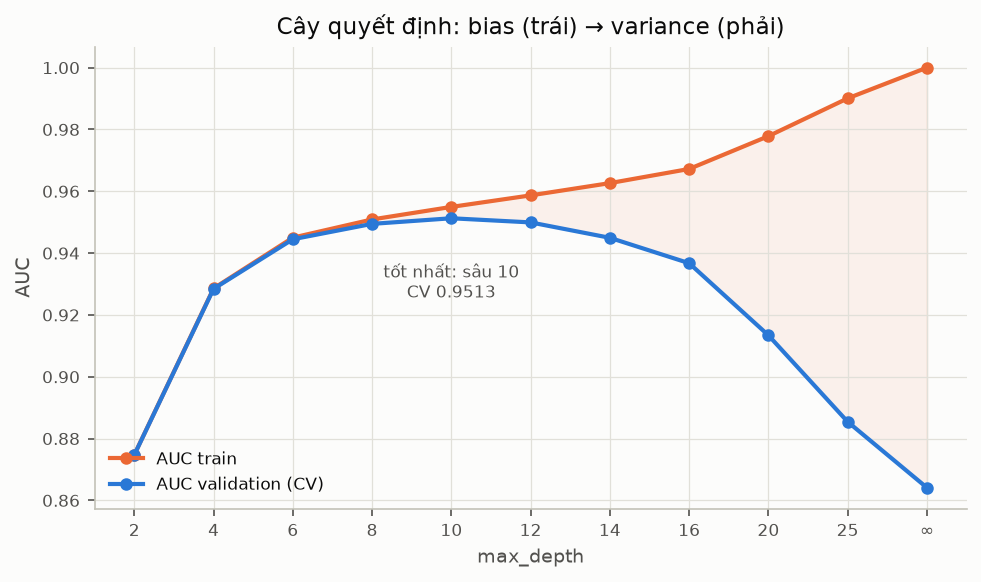

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4))
xs = range(len(dsum))
ax.plot(xs, dsum["train_auc"], color=P.ORANGE, marker="o", label="AUC train")
ax.plot(xs, dsum["val_auc"], color=P.BLUE, marker="o", label="AUC validation (CV)")
ax.fill_between(xs, dsum["val_auc"], dsum["train_auc"], color=P.ORANGE, alpha=0.08)
b = list(dsum.index).index(best_depth)
ax.annotate(f"tốt nhất: sâu {best_depth}\nCV {dsum['val_auc'].iloc[b]:.4f}", (b, dsum["val_auc"].iloc[b]),
            textcoords="offset points", xytext=(0, -38), ha="center", fontsize=8, color=P.INK_2)
ax.set_xticks(xs, [d.replace("không giới hạn", "∞") for d in dsum.index])
ax.set_xlabel("max_depth")
ax.set_ylabel("AUC")
ax.set_title("Cây quyết định: bias (trái) → variance (phải)")
ax.legend(loc="lower left")
P.save(fig, "E3_01_tree_depth")

**Nhận xét 2.1**
- Cây nông bị underfit. Ở độ sâu 2 cây chỉ có 4 lá, AUC train và CV cùng khoảng 0,875; khoảng cách train – CV gần
  bằng 0 nhưng cả hai đều thấp, tức lỗi chủ yếu do bias.
- CV tăng tới độ sâu 10 (**0,9513**, 722 lá) rồi giảm dần. Từ độ sâu 12 trở đi AUC train vẫn tăng còn CV giảm, tức
  lỗi chủ yếu do variance. Cây không giới hạn có 63 nghìn lá, **AUC train bằng 1,0 nhưng CV chỉ 0,864**.
- Độ sâu tốt nhất nằm ở chỗ cân bằng hai loại lỗi, khớp với đường cong bias – variance trong Bài 07. Mục 2.2 xem
  bagging và boosting xử lý hai loại lỗi này như thế nào.

### 2.2 Bảng so sánh 14 model

In [8]:
kag = pd.read_csv(KAGGLE_DIR / "E3_models.csv")
kag["chạy ở"] = "Kaggle CPU"
loc = pd.read_csv(LOCAL)
loc["chạy ở"] = "máy cá nhân"
NAMES = {"lightgbm": "LightGBM", "xgboost": "XGBoost", "catboost": "CatBoost", "hist_gb": "HistGradientBoosting",
         "random_forest": "Random Forest", "extra_trees": "Extra Trees", "mlp": "MLP (256-128)",
         "logistic_regression": "Logistic Regression", "linear_svm": "SVM tuyến tính", "rbf_svm": "SVM RBF (Nyström)",
         "decision_tree": f"Cây quyết định (sâu {best_depth})", "decision_tree_full": "Cây quyết định (không giới hạn)",
         "naive_bayes_cat": "Naive Bayes (categorical)", "naive_bayes_gauss": "Naive Bayes (Gaussian)"}
allm = pd.concat([kag, loc], ignore_index=True)
allm["tên"] = allm["model"].map(NAMES)
allm = allm.sort_values("cv_auc", ascending=False).reset_index(drop=True)
allm["Δ so với LightGBM"] = allm["cv_auc"] - allm.loc[allm["model"] == "lightgbm", "cv_auc"].item()
allm.to_csv(RESULTS_DIR / "E3_all_models.csv", index=False)
allm[["tên", "family", "cv_auc", "Δ so với LightGBM", "fold_std", "train_auc", "train_minus_cv", "minutes", "chạy ở"]]

,tên,family,cv_auc,Δ so với LightGBM,fold_std,train_auc,train_minus_cv,minutes,chạy ở
0,LightGBM,boosting,0.958595,0.000000,0.000607,0.968946,0.010331,3.1,Kaggle CPU
1,XGBoost,boosting,0.958585,-0.000010,0.000611,0.968741,0.010142,3.1,Kaggle CPU
2,CatBoost,boosting,0.958555,-0.000040,0.000606,0.965008,0.006445,29.0,Kaggle CPU
3,HistGradientBoosting,boosting,0.958241,-0.000354,0.000603,0.966158,0.007910,2.0,Kaggle CPU
4,Random Forest,bagging,0.956545,-0.002050,0.000427,0.988357,0.031810,12.8,Kaggle CPU
5,MLP (256-128),mạng nơ-ron,0.956163,-0.002432,0.000827,0.961981,0.005588,7.4,Kaggle CPU
6,Extra Trees,bagging,0.956089,-0.002506,0.000491,0.982731,0.026639,9.6,Kaggle CPU
7,SVM RBF (Nyström),SVM,0.951787,-0.006808,0.000548,0.952301,0.000516,5.6,máy cá nhân
8,Cây quyết định (sâu 10),cây đơn,0.951289,-0.007306,0.000600,0.954953,0.003673,0.3,máy cá nhân
9,Logistic Regression,tuyến tính,0.948675,-0.009920,0.000495,0.948901,0.000223,0.5,máy cá nhân


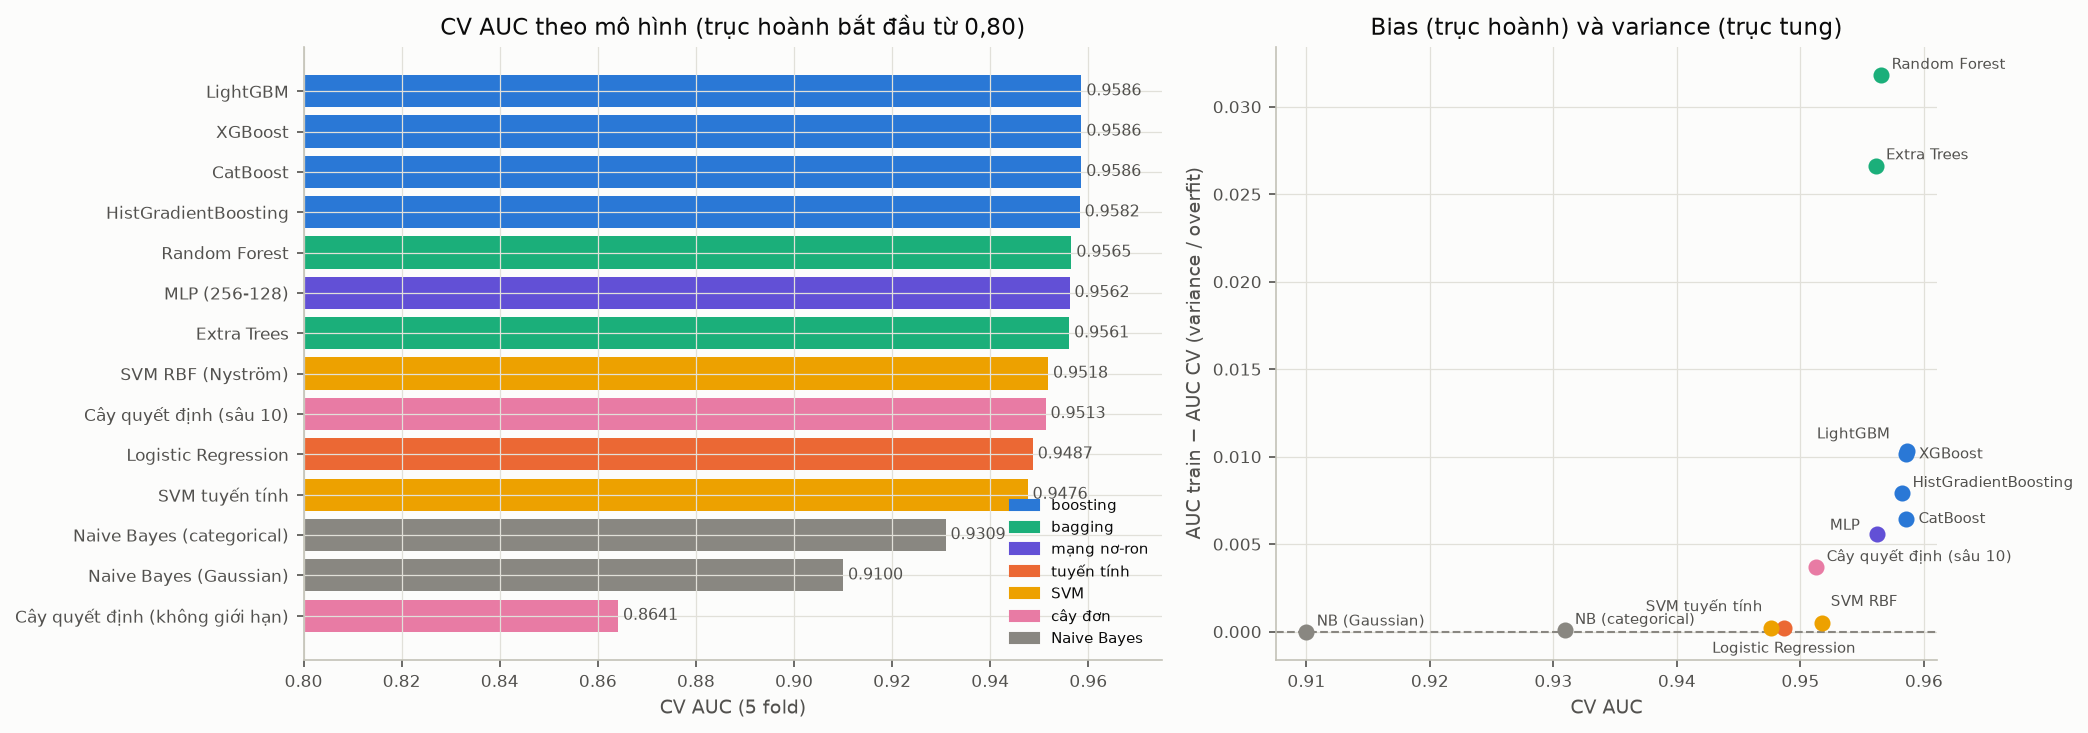

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
d = allm.iloc[::-1]
fam_color = {"boosting": P.BLUE, "bagging": P.AQUA, "mạng nơ-ron": P.SERIES[6], "tuyến tính": P.ORANGE,
             "SVM": P.SERIES[3], "cây đơn": P.SERIES[4], "Naive Bayes": P.INK_3}
ax = axes[0]
ax.barh(d["tên"], d["cv_auc"], color=[fam_color[f] for f in d["family"]])
for i, v in enumerate(d["cv_auc"]):
    ax.text(v + 0.001, i, f"{v:.4f}", va="center", fontsize=7.5, color=P.INK_2)
ax.set_xlim(0.80, 0.975)
ax.set_xlabel("CV AUC (5 fold)")
ax.set_title("CV AUC theo mô hình (trục hoành bắt đầu từ 0,80)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f) for f, c in fam_color.items()], loc="lower right", fontsize=7)
ax = axes[1]
m = allm[allm["model"] != "decision_tree_full"]
OFFSET = {"lightgbm": (-8, 6, "right"), "xgboost": (6, -2, "left"), "catboost": (6, -2, "left"),
          "linear_svm": (-4, 8, "right"), "logistic_regression": (0, -12, "center"), "rbf_svm": (4, 8, "left"),
          "mlp": (-8, 2, "right")}
for _, r in m.iterrows():
    ax.scatter(r["cv_auc"], r["train_minus_cv"], s=45, color=fam_color[r["family"]], zorder=3)
    dx, dy, ha = OFFSET.get(r["model"], (5, 3, "left"))
    lab = r["tên"].replace("Naive Bayes (", "NB (").replace(" (Nyström)", "").replace(" (256-128)", "")
    ax.annotate(lab, (r["cv_auc"], r["train_minus_cv"]), textcoords="offset points", xytext=(dx, dy), ha=ha,
                fontsize=7, color=P.INK_2)
ax.axhline(0, color=P.REF, lw=1, ls="--")
ax.set_xlabel("CV AUC")
ax.set_ylabel("AUC train − AUC CV (variance / overfit)")
ax.set_title("Bias (trục hoành) và variance (trục tung)")
fig.tight_layout()
P.save(fig, "E3_02_models")

**Nhận xét 2.2**
- Bốn model boosting đứng đầu và gần như ngang nhau: LightGBM 0,95860, XGBoost 0,95859, CatBoost 0,95856, HistGB
  0,95824. Ba thư viện đầu chỉ chênh nhau 4×10⁻⁵, nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold (6×10⁻⁴), nên
  không thể nói thư viện nào tốt hơn. CatBoost chạy chậm hơn gần 10 lần (29 phút so với 3 phút trên CPU).
- Hai model bagging (Random Forest 0,95655, Extra Trees 0,95609) có khoảng cách train – CV lớn nhất (0,027–0,032)
  nhưng CV vẫn cao. Từng cây overfit, nhưng lấy trung bình 300 cây làm giảm variance. Boosting thì ngược lại, dùng
  nhiều cây nhỏ để giảm dần bias, và khoảng cách train – CV chỉ 0,006–0,010.
- Một cây quyết định (0,9513) thấp hơn Random Forest 0,0053 và LightGBM 0,0073; đây là mức lợi của ensemble so với
  một cây (Bài 08).
- MLP đạt 0,95616 trên dạng L1, ngang Extra Trees, với khoảng cách train – CV nhỏ (0,006).
- Hai model tuyến tính (LR 0,94868, SVM tuyến tính 0,94763) gần như không overfit (khoảng cách 2×10⁻⁴) nhưng bias
  cao, vì không tự học được tương tác giữa các cột. SVM với kernel RBF (xấp xỉ Nyström) thêm được phần phi tuyến và
  tăng lên 0,95179 dù chỉ fit trên 200 nghìn dòng. Hinge loss (SVM) và log loss (LR) cho kết quả gần nhau.
- Naive Bayes thấp nhất (categorical 0,9309, Gaussian 0,9100). Giả thiết các cột độc lập khi biết nhãn không đúng ở
  đây, vì 13 cột điểm tương quan khá mạnh với nhau (E1). Bản categorical tốt hơn bản Gaussian vì điểm 0–5 là biến
  rời rạc, không có phân phối chuẩn.
- So với E2: trên cùng 21 cột, LR thấp hơn LightGBM 0,0099, nhưng sau khi thêm feature ở E2 thì LR (0,95973) lại cao
  hơn LightGBM chưa thêm feature (0,95860). Feature engineering nâng LR thêm 0,011 nhưng LightGBM chỉ 0,002, cho
  thấy phần lớn feature tạo thêm có tác dụng bù cho việc model tuyến tính không tự học được tương tác.

## 3. Learning curve của LightGBM
LightGBM được train trên 5% đến 100% phần train của fold (25 nghìn đến 504 nghìn dòng) và chấm trên cả fold
validation.

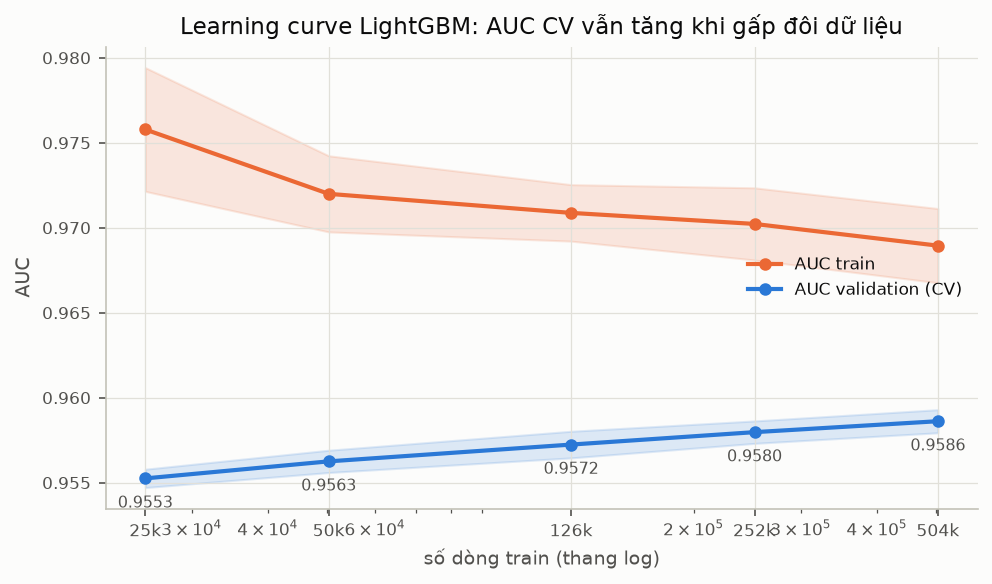

,frac,n_train,val_mean,val_std,train_mean,train_std,gain_vs_prev
0,0.05,25186,0.955251,0.000541,0.975783,0.003642,NaN
1,0.10,50373,0.956252,0.000656,0.971995,0.002240,0.001001
2,0.25,125934,0.957241,0.000783,0.970874,0.001662,0.000988
3,0.50,251869,0.957972,0.000660,0.970225,0.002125,0.000731
4,1.00,503738,0.958615,0.000679,0.968946,0.002184,0.000644


In [10]:
lc = pd.read_csv(KAGGLE_DIR / "E3_learning_curve.csv")
lcs = lc.groupby(["frac", "n_train"])[["val_auc", "train_auc"]].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(7.5, 4))
for col, c, lab in [("train_auc", P.ORANGE, "AUC train"), ("val_auc", P.BLUE, "AUC validation (CV)")]:
    mu, sd = lcs[(col, "mean")], lcs[(col, "std")]
    ax.plot(lcs["n_train"], mu, color=c, marker="o", label=lab)
    ax.fill_between(lcs["n_train"], mu - sd, mu + sd, color=c, alpha=0.15)
for x, v in zip(lcs["n_train"], lcs[("val_auc", "mean")]):
    ax.annotate(f"{v:.4f}", (x, v), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=7.5, color=P.INK_2)
ax.set_xscale("log")
ax.set_xticks(lcs["n_train"], [f"{n / 1000:.0f}k" for n in lcs["n_train"]])
ax.set_xlabel("số dòng train (thang log)")
ax.set_ylabel("AUC")
ax.set_title("Learning curve LightGBM: AUC CV vẫn tăng khi gấp đôi dữ liệu")
ax.legend(loc="center right")
P.save(fig, "E3_03_learning_curve")
lc_tab = lcs.copy()
lc_tab.columns = ["frac", "n_train", "val_mean", "val_std", "train_mean", "train_std"]
lc_tab["gain_vs_prev"] = lc_tab["val_mean"].diff()
lc_tab.round(6)

**Nhận xét mục 3**
- Mỗi lần gấp đôi dữ liệu, CV tăng lần lượt 0,0010, 0,0010, 0,0007 và 0,0006. Mức tăng giảm dần nhưng chưa bão hoà
  ở 504 nghìn dòng. Khoảng cách train – CV thu hẹp từ 0,020 (25 nghìn dòng) xuống 0,010 (504 nghìn dòng), tức thêm
  dữ liệu chủ yếu làm giảm variance.
- Như vậy với bài này, thêm dữ liệu cùng phân phối vẫn còn có ích. Đây có thể là một lý do khiến dữ liệu gốc giúp
  LightGBM tăng 4,8×10⁻⁴ ở E2 dù phân phối delay khác.

## 4. Tương quan giữa các model
Tương quan rank (Spearman) giữa OOF của các model ở mục 2. Hai model có AUC gần nhau nhưng tương quan thấp thường
là cặp có ích khi stacking (E5).

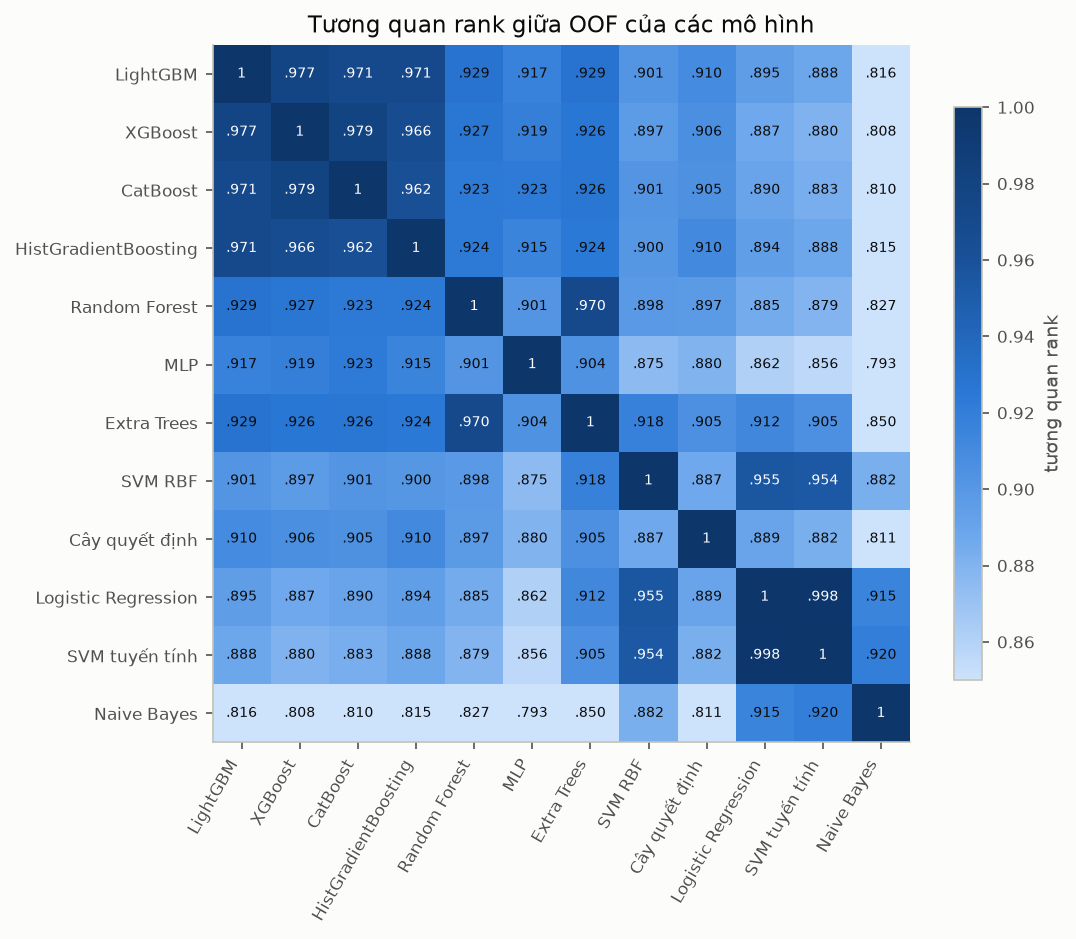

In [11]:
order = [n for n in allm["model"] if n not in ("decision_tree_full", "naive_bayes_gauss")]
R = {}
for n in order:
    p = KAGGLE_DIR / f"oof_E3_{n}.npy"
    R[n] = rankdata(np.load(p if p.exists() else OOF_DIR / f"oof_E3_{n}.npy"))
corr = pd.DataFrame(np.corrcoef(np.vstack([R[n] for n in order])), index=order, columns=order)
corr.to_csv(RESULTS_DIR / "E3_rank_corr.csv")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr.values, cmap=P.SEQ, vmin=0.85, vmax=1)
lab = [NAMES[n].split(" (")[0] for n in order]
ax.set_xticks(range(len(order)), lab, rotation=60, ha="right")
ax.set_yticks(range(len(order)), lab)
for i in range(len(order)):
    for j in range(len(order)):
        v = corr.values[i, j]
        ax.text(j, i, "1" if i == j else f"{v:.3f}"[1:], ha="center", va="center", fontsize=6.5, color="white" if v > 0.95 else P.INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="tương quan rank")
ax.set_title("Tương quan rank giữa OOF của các mô hình")
P.save(fig, "E3_04_rank_corr")

**Nhận xét mục 4**
- Bốn model boosting tương quan rank 0,96–0,98 với nhau, nên ghép chúng lại khó thêm được thông tin.
- Các model khác loại tương quan với LightGBM thấp hơn: MLP 0,917, Random Forest 0,929, SVM RBF 0,901, LR 0,895,
  Naive Bayes 0,816. Trong số này MLP là ứng viên đáng chú ý cho stacking, vì AUC chỉ thấp hơn LightGBM 0,0024 trong
  khi tương quan thấp. E5 kiểm tra điều này.

## 5. Tóm tắt và quyết định

| | Kết quả |
| --- | --- |
| Model đơn tốt nhất trên 21 cột gốc | boosting: LightGBM 0,95860 ≈ XGBoost ≈ CatBoost (chênh 4×10⁻⁵, nhỏ hơn độ lệch giữa fold) |
| Bias / variance | cây sâu 2: bias (0,875); cây không giới hạn: variance (train 1,0, CV 0,864); tốt nhất sâu 10 (0,9513) |
| Ensemble so với một cây | Random Forest +0,0053, LightGBM +0,0073 |
| Model tuyến tính, SVM, Naive Bayes | LR 0,9487, SVM RBF 0,9518, Naive Bayes 0,910–0,931 |
| Learning curve | gấp đôi dữ liệu: +0,0010 → +0,0006, chưa bão hoà |
| Stacking 25 OOF sạch của nhóm (khi thi) | 0,961619; Q-FT đóng góp 2,25×10⁻⁴, các họ khác không quá 5×10⁻⁵ |

**Quyết định:**
1. Dùng LightGBM làm model chính để tinh chỉnh ở E4, vì AUC ngang XGBoost và CatBoost nhưng chạy nhanh hơn CatBoost
   khoảng 10 lần.
2. Model đưa vào stacking được chọn theo mức đóng góp cho stacking (Δ khi bỏ ra, ổn định qua nhiều meta seed), không
   theo AUC riêng. Ưu tiên model khác loại với cây (mạng nơ-ron, model có tiền huấn luyện) như Q-FT. Áp dụng ở E5.
3. Chỉ OOF sạch được đưa vào stacking (quy ước E0), kể cả với model đã dùng khi thi.

**Đã thử nhưng không giữ**

| Ý tưởng | Thời điểm | Kết quả | Δ stack | Lý do không giữ |
| --- | --- | --- | --- | --- |
| kNN k=50 trên không gian feature tự chọn thang | 15/10, 18/10 | 0,9503 | +1×10⁻⁶ / +6×10⁻⁶ | AUC quá thấp dù tương quan thấp |
| Factorization Machine | 18/10 | 0,9572 | ±1×10⁻⁶ | không thêm thông tin |
| TabM | 15/10 | 0,9595 | +4×10⁻⁶ | tương quan cao với model cây |
| FT-Transformer | 18/10 | 0,9601 | +5×10⁻⁶ | tương quan cao với model cây |
| RealMLP-TD (pytabkit, 16 epoch) | 19/10 | 0,9577, tương quan 0,926 với LightGBM | ±1×10⁻⁶ | AUC thấp, có thể do train ít epoch (chưa thử thêm) |
| GPT-2 phân loại dòng dạng văn bản | 19/10 | 0,9562 (5,8 giờ GPU) | −5×10⁻⁶ / −3×10⁻⁶ | dưới ngưỡng, chi phí cao |
| LLR: distilgpt2 sinh dòng theo nhãn, chỉ train trên dữ liệu gốc | 18/10 | 0,9515 | −3,5×10⁻⁶ đến +0,4×10⁻⁶ (stacking khi thi) | dưới ngưỡng |
| TabPFN (context 300 nghìn dòng) | 16/10 | 0,9600 (fold 0) | −3,9×10⁻⁶ đến −0,1×10⁻⁶ (stacking khi thi) | tương quan 0,993 với stacking; hết bộ nhớ GPU khi dùng cả 560 nghìn dòng |
| Chạy lại sạch một member công khai (LightGBM feature nghiệp vụ) | 19/10 | 0,9587 | 0 | bản sạch không giúp; phần lợi của bản gốc nhiều khả năng do early stopping trên fold đang chấm |
| LightGBM trọng số ×3 cho Personal Travel | 18/10 | 0,9605; AUC nhóm Personal không tăng | −1×10⁻⁶ (stacking khi thi) | không cải thiện nhóm khách khó |
| Dual-Specialist LightGBM (2 nhánh Personal / Business) | 18/10 | 0,9586; AUC nhóm Personal giảm từ 0,8336 xuống 0,8284 | – | không sạch (early stopping trên fold đang chấm) |
| Q-FT v1 (khởi tạo mặc định) | 24/10 | 0,8292 | – | không học được (loss tiền huấn luyện không giảm) |
| Q-FT v3 (fine-tune 4 epoch) | 25/10 | 0,9593, thấp hơn v2 ở 5/5 fold | – | AUC giảm ở epoch 4 (overfit) |
| Q-FT v4 (bỏ teacher LightGBM khỏi token) | 25/10 | 0,9610, thấp hơn v2 ở 4/5 fold | −0,9×10⁻⁶ đến −0,2×10⁻⁶ | không khác biệt hơn v2 |
| Cây quyết định không giới hạn độ sâu | kiểm chứng | 0,8641 (train 1,0) | – | overfit |
| Naive Bayes Gaussian / categorical | kiểm chứng | 0,9100 / 0,9309 | – | giả thiết độc lập không đúng vì các cột điểm tương quan mạnh |
| EBM, Explainable Boosting Machine (`A_alt_trees.py`) | 18/10 | 0,9546 (fold 0, train trên 100 nghìn dòng) | – | chạy đủ dữ liệu quá chậm (21 phút cho 100 nghìn dòng); dừng |
| YDF với split xiên (`A_alt_trees.py`) | 18/10 | 0,9565 (fold 0, 100 nghìn dòng) | – | hết RAM khi chạy đủ dữ liệu; dừng |
| RGF, Regularized Greedy Forest (`A_alt_trees.py`) | 18–19/10 | – | – | sau 4 giờ chưa xong fold 0 (máy hết RAM); dừng |
| TabDPT, foundation model truy xuất 2.048 dòng làm context (`A_tabdpt_probe.py`) | 19/10 | 0,9529 (fold 0) | −2,8×10⁻⁶ đến −1,1×10⁻⁵ (stacking khi thi) | không giúp |
| OOF công khai mới: LightGBM + target encoding 4 khoá; TabM (pytabkit) | 26–27/10 | 0,9604 / 0,9605 | −1,7×10⁻⁶ đến +0,8×10⁻⁶ (stacking khi thi) | không thêm thông tin; cả hai early stopping trên fold đang chấm |